In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
movie = pd.read_csv('India Movie.csv', encoding='latin-1')

In [ ]:
movie.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB


In [ ]:
movie.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [ ]:
movie.shape

(15509, 10)

In [ ]:
movie = movie.dropna(subset=['Rating']).reset_index(drop=True)
movie['Year'] = movie['Year'].astype(str).str.extract(r'(\d{4})').astype(float)
movie['Duration'] = movie['Duration'].astype(str).str.extract(r'(\d+)').astype(float)
movie['Votes'] = movie['Votes'].astype(str).str.replace(',', '').astype(float)

In [ ]:
movie['Duration'] = movie['Duration'].fillna(movie['Duration'].median())
movie['Votes'] = movie['Votes'].fillna(movie['Votes'].median())

In [ ]:
movie.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7919 entries, 0 to 7918
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      7919 non-null   object 
 1   Year      7919 non-null   float64
 2   Duration  7919 non-null   float64
 3   Genre     7817 non-null   object 
 4   Rating    7919 non-null   float64
 5   Votes     7919 non-null   float64
 6   Director  7914 non-null   object 
 7   Actor 1   7794 non-null   object 
 8   Actor 2   7719 non-null   object 
 9   Actor 3   7627 non-null   object 
dtypes: float64(4), object(6)
memory usage: 618.8+ KB


In [ ]:
for col in ['Genre', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']:
  movie[col + '_encoded'] = movie.groupby(col)['Rating'].transform('mean')

encoded_cols = [c + '_encoded' for c in ['Genre', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']]
movie[encoded_cols] = movie[encoded_cols].fillna(movie['Rating'].mean())

In [ ]:
features = ['Year', 'Duration', 'Votes', 'Genre_encoded',
            'Director_encoded', 'Actor 1_encoded', 'Actor 2_encoded', 'Actor 3_encoded']

X = movie[features]
y = movie['Rating']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (6335, 8)
X_test shape: (1584, 8)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R2 Score:", r2)

MSE: 0.3770098263888889
R2 Score: 0.7972133438389909


In [ ]:
feature_importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("Feature Importances:")
print(feature_importances)

sample_movie = pd.DataFrame([{
    'Year': 2023,
    'Duration': 140,
    'Votes': 50000,
    'Genre_encoded': movie['Genre_encoded'].mean(),
    'Director_encoded': movie['Director_encoded'].mean(),
    'Actor 1_encoded': movie['Actor 1_encoded'].mean(),
    'Actor 2_encoded': movie['Actor 2_encoded'].mean(),
    'Actor 3_encoded': movie['Actor 3_encoded'].mean()
}])

predicted_rating = model.predict(sample_movie)
print("Predicted Rating:", (predicted_rating[0], 2))

Feature Importances:
Director_encoded    0.611341
Actor 3_encoded     0.106146
Actor 2_encoded     0.096112
Actor 1_encoded     0.076463
Votes               0.045826
Year                0.024646
Genre_encoded       0.022039
Duration            0.017427
dtype: float64
Predicted Rating: (np.float64(6.385000000000002), 2)


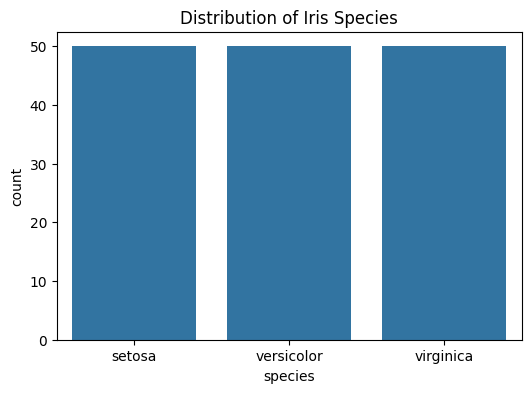

In [ ]:
iris = sns.load_dataset('iris')

plt.figure(figsize=(6, 4))
sns.countplot(data=iris, x='species')
plt.title('Distribution of Iris Species')
plt.show()